Original records: 2254
Sampled records: 300

Domain distribution:
Agriculture, Fisheries, Forestry and Food original=  64 sample=  9
Economy                                  original= 221 sample= 29
Education, Culture and Sport             original=  51 sample=  7
Energy                                   original= 101 sample= 13
Environment                              original= 594 sample= 79
Government and Public Sector             original=  98 sample= 13
Health                                   original= 248 sample= 33
INTERNATIONAL ISSUES                     original=  24 sample=  3
Justice and Public Safety                original=   4 sample=  1
Population and Society                   original= 262 sample= 35
Regions and Cities                       original=   6 sample=  1
Science and Technology                   original= 484 sample= 64
Transport                                original=  97 sample= 13


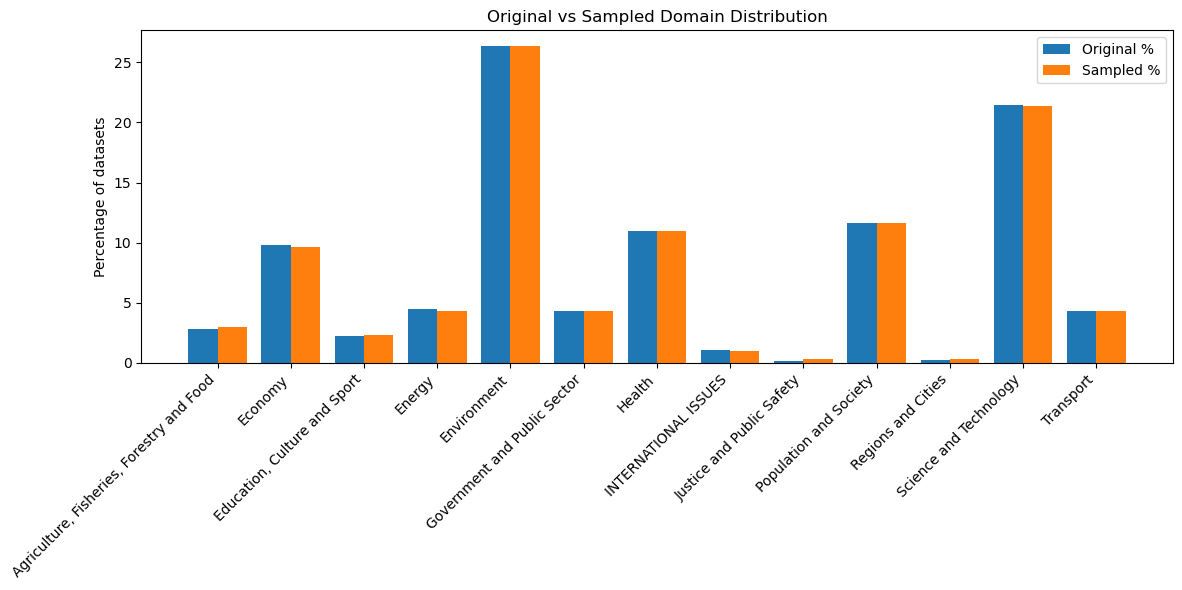


Saved to: gov_data_be_sampled_300.json


In [3]:
import json
import matplotlib.pyplot as plt
import random
from collections import defaultdict, Counter

# Configuration

INPUT_FILE = "gov_data_be_normalized.json"
OUTPUT_FILE = "gov_data_be_sampled_300.json"
SAMPLE_SIZE = 300
RANDOM_SEED = 42

# Load data

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

total_records = len(data)

# Group by primary domain
domain_groups = defaultdict(list)

for record in data:
    domains = record.get("domains", [])
    primary_domain = domains[0] if domains else "Unknown"
    domain_groups[primary_domain].append(record)

domain_counts = {
    domain: len(records)
    for domain, records in domain_groups.items()
}

# Compute proportional allocation
allocations = {}

for domain, count in domain_counts.items():
    allocations[domain] = (count / total_records) * SAMPLE_SIZE

# Floor allocations
sample_counts = {
    domain: int(value)
    for domain, value in allocations.items()
}

# Distribute remaining samples by largest remainder
assigned = sum(sample_counts.values())
remaining = SAMPLE_SIZE - assigned

remainders = sorted(
    [
        (domain, allocations[domain] - sample_counts[domain])
        for domain in allocations
    ],
    key=lambda x: x[1],
    reverse=True
)

for domain, _ in remainders[:remaining]:
    sample_counts[domain] += 1

# Sample records
random.seed(RANDOM_SEED)

sampled_data = []

for domain, records in domain_groups.items():
    n = sample_counts[domain]

    if n >= len(records):
        sampled_data.extend(records)
    else:
        sampled_data.extend(random.sample(records, n))

# Shuffle final output
random.shuffle(sampled_data)

# Save sampled dataset

with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    json.dump(sampled_data, f, indent=2, ensure_ascii=False)

# Print summary
print(f"Original records: {total_records}")
print(f"Sampled records: {len(sampled_data)}")
print()

print("Domain distribution:")
for domain in sorted(sample_counts):
    print(
        f"{domain:<40} "
        f"original={domain_counts[domain]:4d} "
        f"sample={sample_counts[domain]:3d}"
    )
# Prepare data for plotting

domains = sorted(domain_counts.keys())

original_pct = [
    domain_counts[d] / total_records * 100
    for d in domains
]

sampled_pct = [
    sample_counts[d] / len(sampled_data) * 100
    for d in domains
]

x = list(range(len(domains)))
width = 0.4

plt.figure(figsize=(12, 6))

plt.bar(
    [i - width/2 for i in x],
    original_pct,
    width=width,
    label="Original %"
)

plt.bar(
    [i + width/2 for i in x],
    sampled_pct,
    width=width,
    label="Sampled %"
)

plt.xticks(x, domains, rotation=45, ha="right")
plt.ylabel("Percentage of datasets")
plt.title("Original vs Sampled Domain Distribution")
plt.legend()
plt.tight_layout()

plt.show()
print(f"\nSaved to: {OUTPUT_FILE}")